# Plotting

In [1]:
%load_ext autoreload 
%autoreload 2
# reload modules imported 
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from lib.latex_plots import configure_matplotlib
configure_matplotlib()


In [2]:
DATA = Path('../data')
FIGS = Path('../plots/adri')
FIGS.mkdir(exist_ok=True)
EXTERNAL = DATA/'external'
PROCESSED = DATA/'processed'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Cargar ----------
works  = pd.read_parquet(EXTERNAL/'works.parquet')
papers = pd.read_parquet(EXTERNAL/'papers_cleaned.gencat.parquet')
hosts  = pd.read_parquet(EXTERNAL/'host_orgs.parquet')
fields = pd.read_parquet(EXTERNAL/'fields.parquet')

In [4]:

# ---------- 2. Normalizar DOI ----------
def norm_doi(s):
    return (s.astype(str).str.strip().str.lower()
            .str.replace(r'^https?://(dx\.)?doi\.org/', '', regex=True))

works['doi_key']  = norm_doi(works['doi'])
papers['doi_key'] = norm_doi(papers['doi'])

# 1 fila por DOI (evita duplicados preprint/publicado)
papers = papers.dropna(subset=['doi_key']).drop_duplicates('doi_key')
works  = works.drop_duplicates('doi_key')

# ---------- 3. Merge papers ↔ works ----------
df = papers[['doi_key', 'date']].merge(works, on='doi_key', how='inner')

# ---------- 4. Año ----------
df['year'] = pd.to_datetime(df['date'], errors='coerce').dt.year
df = df.dropna(subset=['year'])
df['year'] = df['year'].astype(int)

# ---------- 5. Join con hosts (nombre del publisher) ----------
# Columna en `works` que contiene el openalex_id del publisher
dup = hosts['openalex_id'].duplicated().sum()
if dup:
    print(f'⚠️ {dup} openalex_id duplicados en host_orgs '
          f'(paper con >1 host org). Me quedo con el primero.')

hosts_small = (hosts[['openalex_id', 'host_organization_name']]

               .drop_duplicates('openalex_id', keep='first'))

df = df.merge(hosts_small, on='openalex_id', how='left')


# ---------- 6. Campo APC ----------
APC_COL = 'apc_list_value_usd'   # o 'apc_list_value_usd'
df[APC_COL] = pd.to_numeric(df[APC_COL], errors='coerce').fillna(0)

# ---------- 7. Clasificar editoriales ----------
name = df['host_organization_name'].fillna('').str.lower()
df['group'] = np.select(
    [name.str.contains('elsevier',  na=False),
     name.str.contains('springer',  na=False),
     name.str.contains('oxford',    na=False),
     name.str.contains('wiley',     na=False)],
    ['Elsevier', 'Springer', 'Oxford', 'Wiley'],
    default='Others',
)

# ---------- 8. Agregar por año ----------
order = ['Elsevier', 'Springer', 'Oxford', 'Wiley', 'Others']
pivot_anual = (df.groupby(['year', 'group'])[APC_COL]
           .sum()
           .unstack(fill_value=0)
           .reindex(columns=order, fill_value=0)
           .sort_index())
pivot_anual.to_parquet(PROCESSED/'spent_money_per_year_of_publishers.parquet')
# pivot = pivot_anual.cumsum()
# pivot.round(0)

In [6]:
import matplotlib.ticker as mtick

pivot_anual = pd.read_parquet(PROCESSED/'spent_money_per_year_of_publishers.parquet')
pivot = pivot_anual.avg()
order = ['Elsevier', 'Springer', 'Oxford', 'Wiley', 'Others']

# CVD-safe palette
COLORS = {
    'Elsevier': '#0072B2',
    'Springer': '#E69F00',
    'Oxford':   '#009E73',
    'Wiley':    '#CC79A7',
    'Others':   '#999999',
}
colors = [COLORS[g] for g in order]

# Secondary encoding (redundant with color, CVD-friendly)
HATCHES = ['', '//', '\\\\', '..', 'xx']   # '\\\\' = 2 backslashes en el string

# Scale by millions
# pivot_m = pivot / 1e6

# Thin hatch strokes (por defecto 1.0)
plt.rcParams['hatch.linewidth'] = 0.5

# ---------- 9. Stacked area plot (millones USD) ----------
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
pivot.plot(kind='area', stacked=True, ax=ax,
             color=colors, linewidth=0)

# Hatch + edgecolor contrastado (imprescindible para que se vea)
for pc, h in zip(ax.collections, HATCHES):
    pc.set_hatch(h)
    pc.set_edgecolor('white')   # color de la raya
    pc.set_linewidth(0)         # sin contorno de polígono

ax.set_xlabel('Year')
ax.set_xlim(1980, 2026)
ax.set_ylabel('Estimated spent publishing fees (million USD)')
ax.set_title('Catalan produced academial works editorial publishing fee')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:,.0f}'))
ax.legend(title='Editorial', loc='upper left', frameon=False)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS/'apc_stacked_by_year.pdf', bbox_inches='tight')
plt.show()

AttributeError: 'DataFrame' object has no attribute 'avg'

orcid_employments.parquet
Index(['orcid', 'put_code', 'organization', 'organization_address',
       'department', 'role', 'start_date', 'end_date', 'url'],
      dtype='str')
host_orgs.parquet
Index(['openalex_id', 'host_organization_id', 'host_organization_name'],
      dtype='str')
works.parquet
Index(['openalex_id', 'doi', 'apc_paid_value_usd', 'apc_list_value_usd',
       'awards', 'funders', 'primary_topic_field_id', 'topics_field_ids',
       'referenced_works'],
      dtype='str')
papers_cleaned.gencat.parquet
Index(['date', 'doi', 'ruct', 'orcidResearchers', 'orcidUncheckedAuthors',
       'orcidDirectors'],
      dtype='str')
fields.parquet
Index(['field_id', 'field_name', 'domain_id', 'domain_name'], dtype='str')
orcid_employments_index.parquet
Index(['orcid', 'n_employments', 'fetched_at'], dtype='str')


In [12]:
works_funders = works.explode('funders')
mask = ~works_funders['funders'].isna()
works_funders[mask].reset_index()

,index,openalex_id,doi,apc_paid_value_usd,apc_list_value_usd,awards,funders,primary_topic_field_id,topics_field_ids,referenced_works
0,348329,W2122526907,10.1007/s13209-014-0115-9,NaN,NaN,[],F4320321505,20,"[20, 20, 20]","[W148678942, W1004419928, W1504267291, W152885..."
1,348329,W2122526907,10.1007/s13209-014-0115-9,NaN,NaN,[],F4320321837,20,"[20, 20, 20]","[W148678942, W1004419928, W1504267291, W152885..."
2,348329,W2122526907,10.1007/s13209-014-0115-9,NaN,NaN,[],F4320322121,20,"[20, 20, 20]","[W148678942, W1004419928, W1504267291, W152885..."
3,348330,W2162205054,10.1136/heartjnl-2013-305196,NaN,NaN,[],F4320321714,27,"[27, 27, 27]","[W1557989049, W1567606684, W1592263067, W19843..."
4,348330,W2162205054,10.1136/heartjnl-2013-305196,NaN,NaN,[],F4320334684,27,"[27, 27, 27]","[W1557989049, W1567606684, W1592263067, W19843..."
...,...,...,...,...,...,...,...,...,...,...
258,348414,W4297053029,10.1007/s13593-022-00827-y,2080.0,2080.0,"[CARBOSTOCK (CGL2011-30300, 2012-2014), LIFE18...",F4320321505,11,"[11, 11, 11]","[W1509791622, W1521831729, W1774521583, W19729..."
259,348414,W4297053029,10.1007/s13593-022-00827-y,2080.0,2080.0,"[CARBOSTOCK (CGL2011-30300, 2012-2014), LIFE18...",F4320322649,11,"[11, 11, 11]","[W1509791622, W1521831729, W1774521583, W19729..."
260,348414,W4297053029,10.1007/s13593-022-00827-y,2080.0,2080.0,"[CARBOSTOCK (CGL2011-30300, 2012-2014), LIFE18...",F4320323481,11,"[11, 11, 11]","[W1509791622, W1521831729, W1774521583, W19729..."
261,348414,W4297053029,10.1007/s13593-022-00827-y,2080.0,2080.0,"[CARBOSTOCK (CGL2011-30300, 2012-2014), LIFE18...",F4320333477,11,"[11, 11, 11]","[W1509791622, W1521831729, W1774521583, W19729..."


Shape: (346415, 17)
APC null fraction: 0.728
APC>0 fraction: 0.269

Papers per group:
 group
Others      172554
Elsevier     96432
Springer     34161
Wiley        31834
Oxford       11434
Name: count, dtype: int64

OA coverage by year:
 year
2007    0.375
2008    0.414
2009    0.439
2010    0.479
2011    0.520
2012    0.537
2013    0.560
2014    0.601
2015    0.652
2016    0.677
2017    0.700
2018    0.725
2019    0.748
2020    0.782
2021    0.826
2022    0.847
2023    0.868
2024    0.875
2025    0.864
2026    0.855
Name: is_oa, dtype: float64

Paid-APC coverage by year:
 year
2007    0.041
2008    0.056
2009    0.064
2010    0.079
2011    0.094
2012    0.113
2013    0.128
2014    0.149
2015    0.169
2016    0.179
2017    0.201
2018    0.230
2019    0.271
2020    0.332
2021    0.440
2022    0.500
2023    0.523
2024    0.558
2025    0.582
2026    0.631
Name: has_paid, dtype: float64


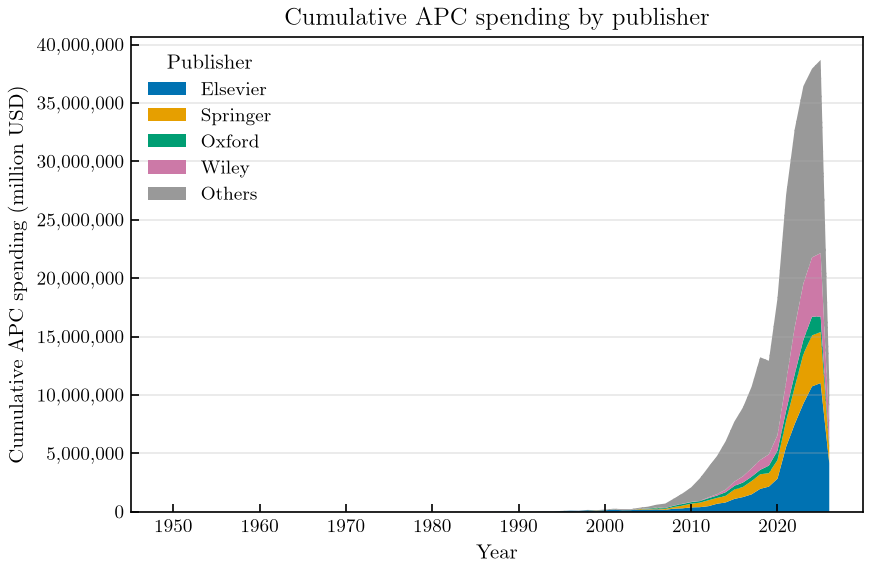

In [ ]:
# =========================================================
# Full pipeline: APC analysis for Catalan-related papers
# ---------------------------------------------------------
# Fuentes: works.parquet, papers_cleaned.gencat.parquet,
#          host_orgs.parquet, works_openaccess.parquet, fields.parquet
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from lib.latex_plots import configure_matplotlib

configure_matplotlib()

# =========================================================
# 1. Config
# =========================================================
FIGS = 'figures'
os.makedirs(FIGS, exist_ok=True)

APC_COL  = 'apc_paid_value_usd'   # o 'apc_list_value_usd'
YEAR_MIN = 2015                   # ajusta según cobertura real
N_MIN    = 10

order_all  = ['Elsevier', 'Springer', 'Oxford', 'Wiley', 'Others']
order_top4 = ['Elsevier', 'Springer', 'Oxford', 'Wiley']

COLORS = {
    'Elsevier': '#0072B2',
    'Springer': '#E69F00',
    'Oxford':   '#009E73',
    'Wiley':    '#CC79A7',
    'Others':   '#999999',
}
HATCHES = {
    'Elsevier': '',
    'Springer': '//',
    'Oxford':   '\\\\',   # 2 backslashes en el literal → 2 en el hatch
    'Wiley':    '..',
    'Others':   'xx',
}
plt.rcParams['hatch.linewidth'] = 0.5

# =========================================================
# 2. Load
# =========================================================
works  = pd.read_parquet('../data/external/works.parquet')
papers = pd.read_parquet('../data/external/papers_cleaned.gencat.parquet')
hosts  = pd.read_parquet('../data/external/host_orgs.parquet')
oa     = pd.read_parquet('../data/external/work_open_access.parquet')
fields = pd.read_parquet('../data/external/fields.parquet')

# =========================================================
# 3. DOI normalization + merge papers <-> works
# =========================================================
def norm_doi(s):
    return (s.astype(str).str.strip().str.lower()
            .str.replace(r'^https?://(dx\.)?doi\.org/', '', regex=True))

works['doi_key']  = norm_doi(works['doi'])
papers['doi_key'] = norm_doi(papers['doi'])

papers = papers.dropna(subset=['doi_key']).drop_duplicates('doi_key')
works  = works.drop_duplicates('doi_key')

df = papers[['doi_key', 'date']].merge(works, on='doi_key', how='inner')

# =========================================================
# 4. Year
# =========================================================
df['year'] = pd.to_datetime(df['date'], errors='coerce').dt.year
df = df.dropna(subset=['year']).copy()
df['year'] = df['year'].astype(int)

# =========================================================
# 5. Publisher name (host_orgs keyed by openalex_id del paper)
# =========================================================
hosts_small = (hosts[['openalex_id', 'host_organization_name']]
               .drop_duplicates('openalex_id', keep='first')
               .rename(columns={'host_organization_name': 'publisher_name'}))
df = df.merge(hosts_small, on='openalex_id', how='left')

# =========================================================
# 6. Open Access (works_openaccess: work_openalex_id → openalex_id)
# =========================================================
if 'work_openalex_id' in oa.columns:
    oa_key = 'work_openalex_id'
else:
    oa_key = [c for c in oa.columns
              if 'openalex_id' in c.lower() and c != 'openalex_id'][0]

if 'is_open_access' in oa.columns:
    oa_small = oa[[oa_key, 'is_open_access']].rename(columns={oa_key: 'openalex_id', 'is_open_access': 'is_oa'})
elif 'oa_status' in oa.columns:
    oa_small = oa[[oa_key, 'oa_status']].rename(columns={oa_key: 'openalex_id'})
    oa_small['is_oa'] = oa_small['oa_status'].isin(
        ['gold', 'hybrid', 'green', 'bronze', 'diamond'])
    oa_small = oa_small[['openalex_id', 'is_oa']]
else:
    raise ValueError(f'No OA column detected in works_openaccess. '
                     f'Available: {list(oa.columns)}')

oa_small = oa_small.drop_duplicates('openalex_id', keep='first')
df = df.merge(oa_small, on='openalex_id', how='left')
df['is_oa'] = df['is_oa'].fillna(False).astype(bool)

# =========================================================
# 7. Fields / domain
# =========================================================
works_fields = (works[['openalex_id', 'primary_topic_field_id']]
                .merge(fields, left_on='primary_topic_field_id',
                       right_on='field_id', how='left'))
df = df.merge(works_fields[['openalex_id', 'field_name', 'domain_name']],
              on='openalex_id', how='left')

# =========================================================
# 8. APC + publisher group
# =========================================================
df[APC_COL] = pd.to_numeric(df[APC_COL], errors='coerce')

name = df['publisher_name'].fillna('').str.lower()
df['group'] = np.select(
    [name.str.contains('elsevier', na=False),
     name.str.contains('springer', na=False),
     name.str.contains('oxford',   na=False),
     name.str.contains('wiley',    na=False)],
    ['Elsevier', 'Springer', 'Oxford', 'Wiley'],
    default='Others',
)

# =========================================================
# 9. Diagnósticos (léelos antes de fiarte de las figuras)
# =========================================================
print('Shape:', df.shape)
print('APC null fraction:', df[APC_COL].isna().mean().round(3))
print('APC>0 fraction:', (df[APC_COL] > 0).mean().round(3))
print('\nPapers per group:\n', df['group'].value_counts())
print('\nOA coverage by year:\n',
      df.groupby('year')['is_oa'].mean().round(3).tail(20))
print('\nPaid-APC coverage by year:\n',
      (df.assign(has_paid=df[APC_COL] > 0)
         .groupby('year')['has_paid'].mean().round(3).tail(20)))

# =========================================================
# 10. Stacked area acumulado por año (millones USD)
# =========================================================
pivot_anual = (df.groupby(['year', 'group'])[APC_COL]
                 .sum().unstack(fill_value=0)
                 .reindex(columns=order_all, fill_value=0)
                 .sort_index())

full_years  = range(int(pivot_anual.index.min()), int(pivot_anual.index.max()) + 1)
pivot_anual = pivot_anual.reindex(full_years, fill_value=0)
pivot_m     = pivot_anual.cumsum() / 1e6

fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
pivot_anual.plot(kind='area', stacked=True, ax=ax,
             color=[COLORS[g] for g in order_all], linewidth=0)

label_to_pc = {pc.get_label(): pc for pc in ax.collections}
for g in order_all:
    pc = label_to_pc.get(g)
    if pc is not None:
        pc.set_hatch(HATCHES[g])
        pc.set_edgecolor('#333333')
        pc.set_linewidth(0)

ax.set_xlabel('Year')
ax.set_ylabel('Cumulative APC spending (million USD)')
ax.set_title('Cumulative APC spending by publisher')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend(title='Publisher', loc='upper left', frameon=False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGS}/apc_stacked_cumulative_by_year.pdf', bbox_inches='tight')
plt.show()


In [21]:
order

['Elsevier', 'Springer', 'Oxford', 'Wiley', 'Others']

year
2002    0.027
2003    0.023
2004    0.028
2005    0.032
2006    0.036
2007    0.041
2008    0.056
2009    0.064
2010    0.079
2011    0.094
2012    0.113
2013    0.128
2014    0.149
2015    0.169
2016    0.179
2017    0.201
2018    0.230
2019    0.271
2020    0.332
2021    0.440
2022    0.500
2023    0.523
2024    0.558
2025    0.582
2026    0.631
Name: has_paid, dtype: float64


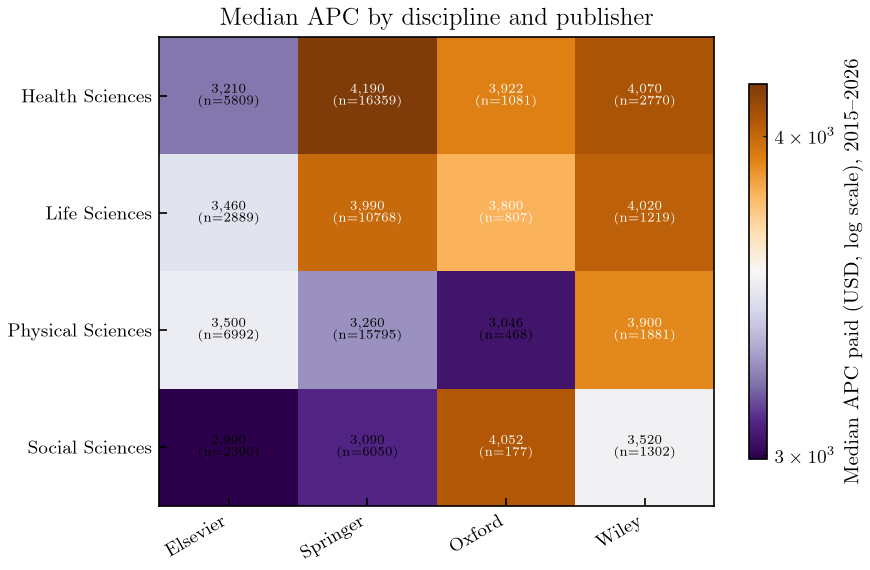

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from lib.latex_plots import configure_matplotlib
configure_matplotlib()
order = ['Elsevier', 'Springer', 'Oxford', 'Wiley']
# --- ¿desde qué año hay cobertura real de APC? ---
cov_year = (df.assign(has_paid=df['apc_paid_value_usd'] > 0)
              .groupby('year')['has_paid'].mean())
print(cov_year.round(3).tail(25))
# Elige YEAR_MIN donde la cobertura sea > ~10-20%

YEAR_MIN = 2015
N_MIN = 10

sub = df[(df['year'] >= YEAR_MIN) & (df['apc_paid_value_usd'] > 0)]

# Mediana + n por celda
agg = (sub.groupby(['domain_name', 'group'])['apc_paid_value_usd']
          .agg(median='median', n='size')
          .reset_index())

med = agg.pivot(index='domain_name', columns='group', values='median')
n   = agg.pivot(index='domain_name', columns='group', values='n')

# Reordena por filas: dominio con mayor mediana global arriba
med = med.reindex(columns=order)
row_order = med.median(axis=1).sort_values(ascending=False).index
med = med.loc[row_order]; n = n.loc[row_order]

# Enmascara celdas con pocos datos
med_plot = med.mask(n < N_MIN)

# --- Figura ---
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
im = ax.imshow(med_plot.values, aspect='auto',
               cmap='PuOr_r',
               norm=LogNorm(vmin=max(med_plot.min().min(), 100),
                            vmax=med_plot.max().max()))

ax.set_xticks(range(len(med_plot.columns)))
ax.set_xticklabels(med_plot.columns, rotation=30, ha='right')
ax.set_yticks(range(len(med_plot.index)))
ax.set_yticklabels(med_plot.index)

# Anotar mediana + n (n en gris pequeño)
for i in range(med_plot.shape[0]):
    for j in range(med_plot.shape[1]):
        v, nn = med_plot.iloc[i, j], n.iloc[i, j]
        if np.isnan(v):
            ax.text(j, i, f'n={int(nn)}' if not np.isnan(nn) else '',
                    ha='center', va='center', fontsize=6, color='lightgray')
        else:
            ax.text(j, i, f'{v:,.0f}\n(n={int(nn)})',
                    ha='center', va='center', fontsize=6,
                    color='white' if v > med_plot.stack().median() else 'black')

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label(f'Median APC paid (USD, log scale), {YEAR_MIN}–{df.year.max()}')
ax.set_title('Median APC by discipline and publisher')
plt.tight_layout()
plt.savefig(FIGS/'apc_heatmap_domain_publisher.pdf', bbox_inches='tight')
plt.show()